<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2014%20PBL/Praktikum%202%20(JS14)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Load Library

In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

#Langkah 2 - Muat dan Gabungkan Dataset Cafes & Reviews

In [3]:
# Memuat dataset
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Menggabungkan data berdasarkan cafe_id
df_merged = pd.merge(df_reviews, df_cafes, on='cafe_id', how='inner', suffixes=('_review', '_cafe'))

# Tentukan target regresi (misal: rating kafe)
target_column = 'rating_cafe' if 'rating_cafe' in df_merged.columns else 'rating'
df_merged = df_merged.dropna(subset=[target_column])

# Ambil fitur numerik untuk direpresentasikan ke citra 32x32x3
feature_cols = ['review_count', 'latitude', 'longitude']
df_features = df_merged[feature_cols].fillna(0)

scaler = MinMaxScaler(feature_range=(0, 255))
scaled_features = scaler.fit_transform(df_features)

# Fungsi konversi data tabular ke citra 32x32x3
def tabular_to_image_32(row_data):
    img = np.zeros((32, 32, 3), dtype=np.uint8)
    val1 = int(np.clip(row_data[0], 0, 255))
    val2 = int(np.clip(row_data[1] * 10 + 128, 0, 255))
    val3 = int(np.clip(row_data[2] * 10 + 128, 0, 255))

    img[:, :, 0] = val1
    img[:, :, 1] = val2
    img[:, :, 2] = val3
    return img

images = np.array([tabular_to_image_32(row) for row in scaled_features])
labels = df_merged[target_column].values

# Membagi data training dan testing
train_images, test_images, train_labels, test_labels = train_test_split(images, labels, test_size=0.2, random_state=42)

# Normalisasi nilai piksel menjadi antara 0 dan 1 (setara dataset CIFAR)
train_images, test_images = train_images / 255.0, test_images / 255.0

print(f"Bentuk train_images: {train_images.shape}")
print(f"Bentuk test_images : {test_images.shape}")

Bentuk train_images: (1784, 32, 32, 3)
Bentuk test_images : (446, 32, 32, 3)


#Langkah 3 - Verifikasi Data

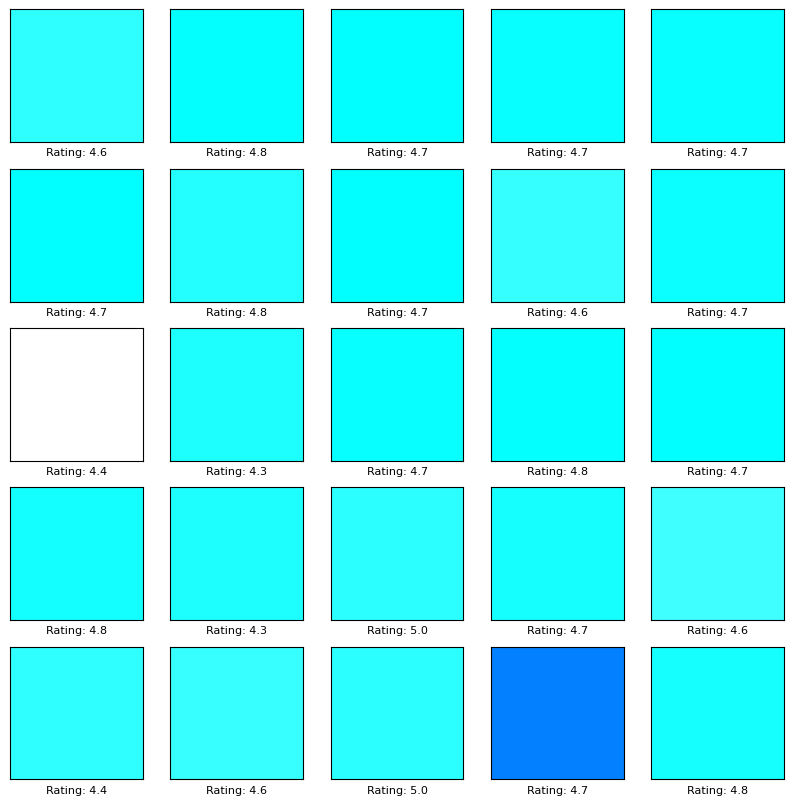

In [4]:
plt.figure(figsize=(10, 10))
for i in range(min(25, len(train_images))):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(f"Rating: {train_labels[i]:.1f}", fontsize=8)
plt.show()

#Langkah 4 - Buat Model CNN

##Langkah 4.1 - Buat Layer Konvolusi

In [5]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


##Langkah 4.2 - Cek Arsitektur Konvolusi

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

##Langkah 4.3 - Tambahkan Layer Fully Connected

In [7]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
# Output layer menggunakan 1 unit tanpa fungsi aktivasi (linear) karena kasus regresi nilai kontinu
model.add(layers.Dense(1))

##Langkah 4.4 - Cek Arsitektur Model CNN Lengkap

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,985 (476.50 KB)

 Trainable params: 121,985 (476.50 KB)

 Non-trainable params: 0 (0.00 B)

##Langkah 4.5 - Compile Model CNN

In [9]:
# Menggunakan loss function Mean Squared Error (MSE) dan metrik MAE untuk regresi
model.compile(optimizer='adam',
              loss='mean_squared_error',
              metrics=['mae'])

#Langkah 5 - Fit Model

In [10]:
history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 1.3111 - mae: 0.6636 - val_loss: 0.0631 - val_mae: 0.1561
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0613 - mae: 0.1569 - val_loss: 0.0579 - val_mae: 0.1504
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - loss: 0.0526 - mae: 0.1477 - val_loss: 0.0501 - val_mae: 0.1586
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - loss: 0.0410 - mae: 0.1408 - val_loss: 0.0480 - val_mae: 0.1720
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 0.0335 - mae: 0.1381 - val_loss: 0.0279 - val_mae: 0.1263
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - loss: 0.0272 - mae: 0.1277 - val_loss: 0.0273 - val_mae: 0.1267
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0311 - mae: 0.1391 - val_loss: 0.0464 - val_mae: 0.1844
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0306 - mae: 0.1373 - val_loss: 0.0308 - val_mae: 0.1446
Epoch 9/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.032

#Langkah 6 - Evaluasi Model (Visualisasi Grafik Loss)

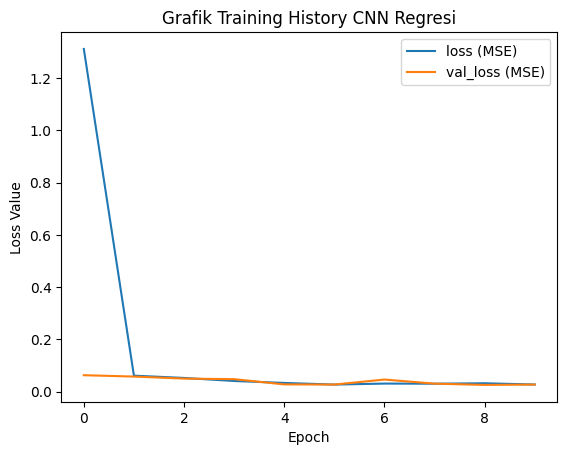

14/14 - 0s - 13ms/step - loss: 0.0273 - mae: 0.1313


In [12]:
plt.plot(history.history['loss'], label='loss (MSE)')
plt.plot(history.history['val_loss'], label='val_loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.legend(loc='upper right')
plt.title('Grafik Training History CNN Regresi')
plt.show()

test_loss, test_mae = model.evaluate(test_images, test_labels, verbose=2)

#Langkah 7 - Cetak Hasil Metrik Evaluasi Akhir

In [15]:
print(f"Test Loss (MSE): {test_loss:.4f}")
print(f"Test MAE      : {test_mae:.4f}")

Test Loss (MSE): 0.0273
Test MAE      : 0.1313
